## Model Evaluation and Error Analysis
---
- The goal is to evaluate the performance of the selected losgistic regression model in order to analyse the miss-classified cases to extract meaningful business insights.

- Focus is not only on the model's performance but also on why and where model is making errors.

### Rebuilding the Final Logistic Regression Model
---
- Since notebooks run independently we recreate the final selected model here to ensure reproducibility and structured workflow.

### Import Required Libraries
---
In this section, we import the necessary Python libraries used for data handling, model training, preprocessing, and evaluation.

These libraries provide tools for:
- Data manipulation (pandas)
- Model training (scikit-learn)
- Data splitting and scaling
- Model evaluation metrics

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

### Load the Final Engineered Dataset
---
- The dataset used here is the final output produced in the Feature Engineering notebook.
- It contains all cleaned and transformed features required for modeling.

In [3]:
df = pd.read_csv("../data/processed/final_model_dataset.csv")
df.head()

,Gender,Age,Scholarship,Hipertension,Diabetes,Alcoholism,SMS_received,No-show,Handcap_binary,WaitingDays
0,0,76,0,1,0,0,0,0,0,1
1,0,23,0,0,0,0,0,1,0,1
2,0,39,0,0,0,0,0,1,0,1
3,0,19,0,0,0,0,0,0,0,1
4,0,30,0,0,0,0,0,0,0,1


### Define Features and Target Variable
---
The dataset is separated into:
- **Feature matrix (X):** All predictor variables used by the model
- **Target variable (y):** The outcome we want to predict (No_Show)


In [4]:
x = df.drop("No-show", axis=1)
y = df["No-show"]

### Train-Test Split
---
The dataset is divided into training and testing sets.
- **Training set:** Used to train the model
- **Testing set:** Used to evaluate model performance on unseen data

- Stratified splitting is used to maintain the same class distribution between training and testing sets since the dataset is imbalanced.

In [5]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

### Feature Scaling and Model Training
---
Feature scaling is applied to standardize numerical variables.

- Logistic Regression performs better when features are on a similar scale.
- The scaler is fitted on the training data and then applied to the test data to prevent data leakage.

The Logistic Regression model is trained using the scaled training dataset.

- Logistic Regression is chosen because it provides interpretable results and performs well as a baseline model for classification tasks.

In [6]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(x_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

### Model Evaluation (Default Threshold)
---
The trained model is evaluated using the default classification threshold
of **0.5**.

Key evaluation metrics include:
- Confusion Matrix
- Precision
- Recall
- F1-score

These metrics help assess how well the model identifies no-show patients.

In [7]:
y_pred = model.predict(x_test_scaled)

print('Confusion Matrix :\n',confusion_matrix(y_test, y_pred))
print('Classification Report :\n',classification_report(y_test,y_pred))

Confusion Matrix :
 [[5499 4480]
 [1722 2265]]
Classification Report :
               precision    recall  f1-score   support

           0       0.76      0.55      0.64      9979
           1       0.34      0.57      0.42      3987

    accuracy                           0.56     13966
   macro avg       0.55      0.56      0.53     13966
weighted avg       0.64      0.56      0.58     13966



### ROC-AUC Evaluation

- The ROC-AUC score is calculated to measure the model’s ability to distinguish between no-show and non–no-show patients across all possible classification thresholds.

A higher AUC indicates better class separation ability.

In [8]:
y_prob = model.predict_proba(x_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_prob)
print("AUC Score :", auc)

AUC Score : 0.5883545940581064


### Threshold Adjustment
---
- Since the dataset is imbalanced and missing risky patients can be costly, the classification threshold is adjusted from the default **0.5 to 0.45**.

This adjustment increases recall for no-show patients while maintaining reasonable model performance.

In [9]:
threshold = 0.45
y_pred_final = (y_prob > threshold).astype(int)

print("Confusion Matrix (Threshold 0.45) :\n", confusion_matrix(y_test, y_pred_final))
print("\nClassification Report :\n", classification_report(y_test, y_pred_final))

Confusion Matrix (Threshold 0.45) :
 [[3366 6613]
 [ 848 3139]]

Classification Report :
               precision    recall  f1-score   support

           0       0.80      0.34      0.47      9979
           1       0.32      0.79      0.46      3987

    accuracy                           0.47     13966
   macro avg       0.56      0.56      0.47     13966
weighted avg       0.66      0.47      0.47     13966



### Preparing Data for Error Analysis
---
To analyze model errors, a new dataframe is created that contains:

- Original test features
- Actual target values
- Model predictions
- Prediction probabilities

This dataset allows us to investigate misclassified cases and identify patterns behind model errors.

In [10]:
error_df = x_test.copy()
error_df['Actual'] = y_test.values
error_df['Predicted'] = y_pred_final
error_df['Probability'] = y_prob

error_df.head()

,Gender,Age,Scholarship,Hipertension,Diabetes,Alcoholism,SMS_received,Handcap_binary,WaitingDays,Actual,Predicted,Probability
56139,1,19,0,0,0,0,1,0,36,0,1,0.564807
47207,1,23,0,0,0,0,0,0,24,1,1,0.571953
52434,0,45,0,0,0,0,0,0,0,0,1,0.463839
27751,0,18,0,0,0,0,1,0,20,1,1,0.537079
53034,0,20,1,0,0,0,1,0,6,1,1,0.568412


### Identify Misclassified Cases
---
To better understand the model’s performance, we analyze the cases where the model made incorrect predictions.

Two important types of errors are:

- **False Negatives:** Patients who actually did not show up but were predicted as showing up.
- **False Positives:** Patients who actually showed up but were predicted as no-show.

Analyzing these groups helps identify patterns behind the model's mistakes and can provide insights for improving future models.

In [11]:
false_negatives = error_df[(error_df['Actual'] == 1) & (error_df['Predicted'] == 0)]
false_positives = error_df[(error_df['Actual'] == 0) & (error_df['Predicted'] == 1)]

print('False Negatives :',len(false_negatives))
print('False Positives :',len(false_positives))

False Negatives : 848
False Positives : 6613


### Inspect Example Misclassifications
---
- We examine a few rows from the false negative and false positive groups to get an initial sense of the feature patterns associated with these errors.

In [12]:
false_negatives.head()

,Gender,Age,Scholarship,Hipertension,Diabetes,Alcoholism,SMS_received,Handcap_binary,WaitingDays,Actual,Predicted,Probability
9200,1,45,0,0,0,0,1,0,14,1,0,0.445574
26335,0,50,0,0,0,0,1,0,5,1,0,0.417150
1086,1,63,0,1,1,0,1,0,2,1,0,0.387344
22810,1,90,0,1,0,0,1,0,34,1,0,0.354055
46262,0,44,0,1,0,0,1,0,3,1,0,0.412607


In [13]:
false_positives.head()

,Gender,Age,Scholarship,Hipertension,Diabetes,Alcoholism,SMS_received,Handcap_binary,WaitingDays,Actual,Predicted,Probability
56139,1,19,0,0,0,0,1,0,36,0,1,0.564807
52434,0,45,0,0,0,0,0,0,0,0,1,0.463839
25802,0,20,1,0,0,0,1,0,17,0,1,0.592097
49585,0,35,0,0,0,0,1,0,20,0,1,0.490606
8358,0,26,0,0,0,0,1,0,54,0,1,0.589433


### Compare Patterns Between Detected and Missed No-Show Patients
---
To understand why some no-show patients are missed by the model, we compare the average feature values between:

- True Positives (correctly detected no-shows)
- False Negatives (missed no-shows)

This helps identify behavioral patterns that the model struggles to capture.

In [14]:
true_positives = error_df[(error_df['Actual'] == 1) & (error_df['Predicted'] == 1)]

print('Average value for Missed No-shows :\n', false_negatives.mean(numeric_only='True'))
print('\nAverage value for Detected No-shows :\n', true_positives.mean(numeric_only='True'))

Average value for Missed No-shows :
 Gender             0.295991
Age               62.679245
Scholarship        0.004717
Hipertension       0.500000
Diabetes           0.160377
Alcoholism         0.000000
SMS_received       0.536557
Handcap_binary     0.028302
WaitingDays        8.905660
Actual             1.000000
Predicted          0.000000
Probability        0.408426
dtype: float64

Average value for Detected No-shows :
 Gender             0.332909
Age               28.503026
Scholarship        0.135712
Hipertension       0.092386
Diabetes           0.044600
Alcoholism         0.036317
SMS_received       0.467028
Handcap_binary     0.013061
WaitingDays       18.848359
Actual             1.000000
Predicted          1.000000
Probability        0.540404
dtype: float64


###  Key Insights from Error Analysis
---

**Age plays a significant role in prediction performance.**  

  - The model performs better for younger patients (average ~28 years), while it frequently misses older patients (average ~62 years).  

  - This indicates that older patients are harder to classify as high-risk.

**Waiting time strongly influences no-show detection.**  

  - Patients with longer waiting periods (~18 days) are more likely to be correctly identified as no-shows, whereas patients with shorter waiting times (~9 days) are often misclassified.

  - This suggests that longer delays increase no-show probability.

**Socioeconomic factors (Scholarship) show noticeable variation.**  

  - Patients receiving scholarships appear more frequently among correctly detected no-shows, indicating that financial or social conditions may influence attendance behavior.

**SMS reminders alone are not sufficient to prevent no-shows.**  

 - A significant portion of missed patients had received SMS reminders, suggesting that additional intervention strategies may be required.

### Conclusion
---

- The error analysis reveals that while the model is able to identify certain patterns associated with no-shows, it struggles with specific patient groups, particularly older individuals and those with shorter waiting times.

- From a business perspective, minimizing false negatives remains critical, as these represent high-risk patients who are not being flagged.

- Overall, the model provides useful insights but has limited predictive strength, indicating room for improvement through better feature engineering or more advanced models.

### Visual Analysis of Model Errors
---

- To better understand the differences between correctly detected and missed no-show patients.

- Visualizations are used to compare key features such as age, waiting time, and SMS reminders.

- These plots help in identifying patterns that may not be immediately interpreted from numerical summaries.

### Age Comparision

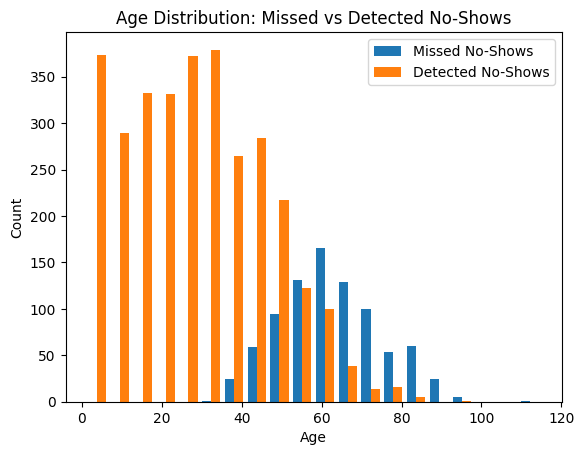

In [22]:
import matplotlib.pyplot as plt

plt.hist([false_negatives["Age"], true_positives["Age"]], 
         bins=20, 
         label=["Missed No-Shows", "Detected No-Shows"])

plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution: Missed vs Detected No-Shows")
plt.legend()
plt.show()

### Waiting Days Comparision

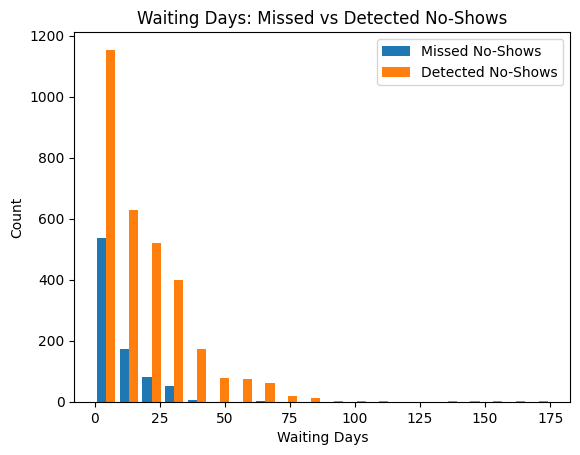

In [24]:
plt.hist([false_negatives["WaitingDays"],true_positives["WaitingDays"]],
         bins=20, 
         label=["Missed No-Shows", "Detected No-Shows"])

plt.xlabel("Waiting Days")
plt.ylabel("Count")
plt.title("Waiting Days: Missed vs Detected No-Shows")
plt.legend()

plt.show()

### SMS Reminder Impact

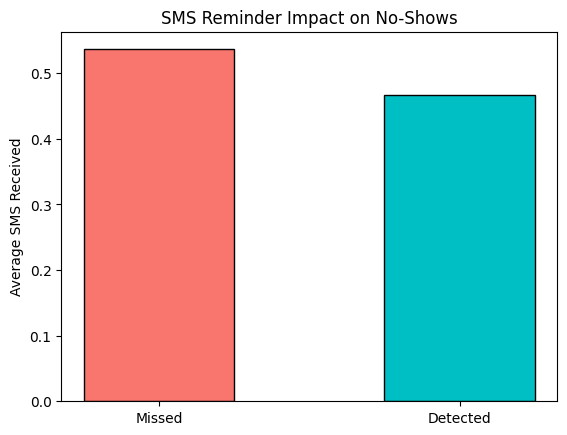

In [26]:
sms_data = [
    false_negatives["SMS_received"].mean(),
    true_positives["SMS_received"].mean()
]

labels = ["Missed", "Detected"]

plt.bar(labels, sms_data,width=0.5, color=['#f8766d', '#00bfc4'], edgecolor='black')

plt.title("SMS Reminder Impact on No-Shows")
plt.ylabel("Average SMS Received")

plt.show()

### Concluding Observations
---

- Comparative Insights: The visualizations clearly distinguish the characteristics of Detected vs. Missed no-shows.

- Feature Influence: Key features (such as Age and Waiting Days) show a direct correlation with the model's predictive performance, suggesting they are primary drivers of the classification logic.

- Strategic Improvements: To enhance accuracy, further feature engineering and model tuning are required. Increasing the model's interpretability will allow for more actionable insights and a more reliable comparison between patient cohorts.